In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("modeling_table_final.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162769 entries, 0 to 162768
Data columns (total 30 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   incident_zip          162769 non-null  int64  
 1   date                  162769 non-null  object 
 2   borough               160951 non-null  object 
 3   request_count         162769 non-null  int64  
 4   complaint_type_count  162769 non-null  int64  
 5   year                  162769 non-null  int64  
 6   month                 162769 non-null  int64  
 7   day_of_week           162769 non-null  int64  
 8   day_of_year           162769 non-null  int64  
 9   season                162769 non-null  int64  
 10  is_weekend            162769 non-null  int64  
 11  is_holiday            162769 non-null  int64  
 12  tmax                  162769 non-null  float64
 13  tmin                  162769 non-null  float64
 14  prcp                  162769 non-null  float64
 15  

In [4]:
df.isnull().sum()

incident_zip               0
date                       0
borough                 1818
request_count              0
complaint_type_count       0
year                       0
month                      0
day_of_week                0
day_of_year                0
season                     0
is_weekend                 0
is_holiday                 0
tmax                       0
tmin                       0
prcp                       0
snow                       0
snwd                       0
awnd                       0
temp_range                 0
lag_request_1d             0
lag_request_7d             0
lag_request_14d            0
rolling_avg_7d             0
rolling_avg_30d            0
rolling_prcp_3d            0
freeze_thaw_7d             0
population                 0
avg_pavement_rating        0
water_breaks_ever          0
water_breaks_30d           0
dtype: int64

### borough has too few nulls and the column itself is not numerical or very important so remove all the dows with null

In [5]:
df=df.dropna(subset=['borough'])

In [6]:
pd.set_option('display.max_columns', None)

In [7]:
df.sample(10)

,incident_zip,date,borough,request_count,complaint_type_count,year,month,day_of_week,day_of_year,season,is_weekend,is_holiday,tmax,tmin,prcp,snow,snwd,awnd,temp_range,lag_request_1d,lag_request_7d,lag_request_14d,rolling_avg_7d,rolling_avg_30d,rolling_prcp_3d,freeze_thaw_7d,population,avg_pavement_rating,water_breaks_ever,water_breaks_30d
983,10001,2024-07-20,MANHATTAN,2,2,2024,7,5,202,2,1,0,28.3,21.7,0.0,0.0,0.0,0.9,6.6,2.0,4.0,6.0,1.857143,2.700000,37.1,0.0,27004.0,6.75,34,0.0
141174,11225,2021-05-23,BROOKLYN,1,1,2021,5,6,143,1,1,0,31.1,20.0,0.0,0.0,0.0,3.2,11.1,2.0,2.0,2.0,2.000000,2.200000,0.0,0.0,58476.0,7.28,80,0.0
137864,11222,2024-06-20,BROOKLYN,7,1,2024,6,3,172,2,0,0,32.8,22.2,0.0,0.0,0.0,1.5,10.6,3.0,2.0,1.0,2.857143,3.566667,0.0,0.0,40137.0,7.28,134,2.0
55014,10309,2022-01-10,STATEN ISLAND,5,2,2022,1,0,10,0,0,0,4.4,-4.3,0.0,0.0,0.0,3.8,8.7,2.0,1.0,1.0,5.571429,3.733333,12.2,1.0,34740.0,6.81,59,2.0
121706,11212,2023-09-19,BROOKLYN,2,1,2023,9,1,262,3,0,0,22.2,14.4,0.0,0.0,0.0,2.0,7.8,3.0,6.0,2.0,3.428571,3.300000,39.3,0.0,84006.0,7.28,130,0.0
51767,10306,2024-07-30,STATEN ISLAND,6,4,2024,7,1,212,2,0,0,31.1,23.9,0.0,0.0,0.0,1.3,7.2,2.0,5.0,8.0,3.285714,5.000000,1.3,0.0,56232.0,6.81,134,2.0
49108,10305,2021-09-10,STATEN ISLAND,4,2,2021,9,4,253,3,0,0,23.3,17.2,0.0,0.0,0.0,2.7,6.1,5.0,13.0,3.0,8.571429,12.833333,6.6,0.0,42211.0,6.81,122,2.0
144448,11228,2022-03-23,BROOKLYN,5,2,2022,3,2,82,1,0,0,9.4,3.3,1.5,0.0,0.0,3.4,6.1,2.0,2.0,1.0,2.571429,3.433333,1.5,0.0,44196.0,7.28,81,3.0
112959,11207,2021-11-24,BROOKLYN,2,2,2021,11,2,328,3,0,0,7.2,-1.0,0.0,0.0,0.0,2.1,8.2,11.0,9.0,5.0,6.571429,5.100000,1.0,1.0,96801.0,7.28,163,0.0
23857,10027,2021-01-09,MANHATTAN,1,1,2021,1,5,9,0,1,0,2.8,-4.3,0.0,0.0,0.0,3.1,7.1,7.0,7.0,2.0,3.714286,2.966667,0.0,1.0,65806.0,6.75,16,2.0


In [8]:
df.columns

Index(['incident_zip', 'date', 'borough', 'request_count',
       'complaint_type_count', 'year', 'month', 'day_of_week', 'day_of_year',
       'season', 'is_weekend', 'is_holiday', 'tmax', 'tmin', 'prcp', 'snow',
       'snwd', 'awnd', 'temp_range', 'lag_request_1d', 'lag_request_7d',
       'lag_request_14d', 'rolling_avg_7d', 'rolling_avg_30d',
       'rolling_prcp_3d', 'freeze_thaw_7d', 'population',
       'avg_pavement_rating', 'water_breaks_ever', 'water_breaks_30d'],
      dtype='object')

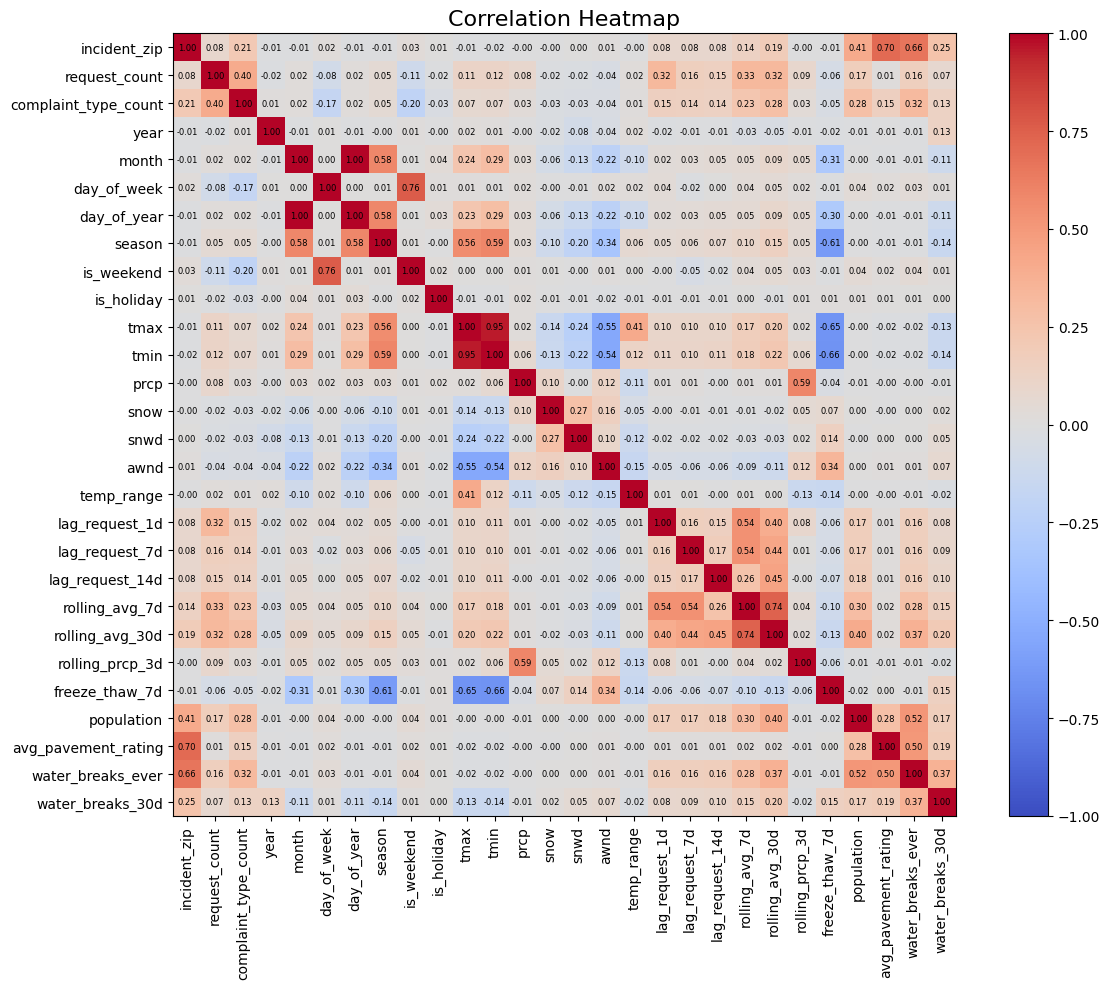

In [9]:
import matplotlib.pyplot as plt
import numpy as np

numeric_df = df.select_dtypes(include=['int64', 'float64'])
corr = numeric_df.corr()

plt.figure(figsize=(14, 10))  # BIG figure

im = plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)

# Axis labels
plt.xticks(ticks=np.arange(len(corr.columns)), labels=corr.columns, rotation=90)
plt.yticks(ticks=np.arange(len(corr.columns)), labels=corr.columns)

# Annotate values (optional but powerful)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha='center', va='center', fontsize=6)

plt.title("Correlation Heatmap", fontsize=16)
plt.tight_layout()
plt.show()

### 

lag_request_1d → Yesterday’s complaints directly influence today’s because patterns persist short-term.
lag_request_7d → Complaints repeat weekly, so same-day-last-week is a strong signal.
rolling_avg_7d → Averages reduce noise and reveal the true underlying trend.
population → More people naturally generate more complaints (scale effect).
water_breaks_ever → Poor infrastructure leads to consistently higher complaint volume.
complaint_type_count → Some complaint types are inherently more frequent than others.

C:\Users\hs264\AppData\Local\Temp\ipykernel_10796\1889284307.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='prcp_category', y='request_count', data=df, showfliers=False, palette='Set2')


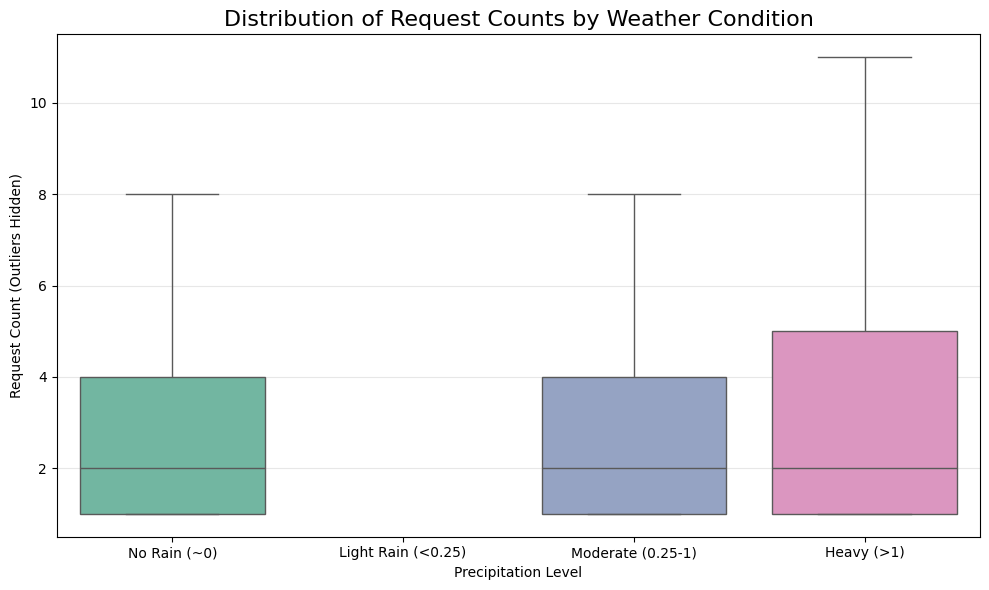

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plt.figure(figsize=(10, 6))

# 1. Create logical precipitation bins
max_prcp = df['prcp'].max()
bins = [-0.01, 0.01, 0.25, 1.0, max_prcp + 0.1]
labels = ['No Rain (~0)', 'Light Rain (<0.25)', 'Moderate (0.25-1)', 'Heavy (>1)']

# Apply the bins to a temporary column
df['prcp_category'] = pd.cut(df['prcp'], bins=bins, labels=labels)

# 2. Plot the boxplot
# showfliers=False is crucial: it hides extreme outliers so you can actually see the main "boxes"
sns.boxplot(x='prcp_category', y='request_count', data=df, showfliers=False, palette='Set2')

plt.title("Distribution of Request Counts by Weather Condition", fontsize=16)
plt.xlabel("Precipitation Level")
plt.ylabel("Request Count (Outliers Hidden)")

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### normal rain dont play much role but when it gets heavy (outliers included) it affects the complaints a lot

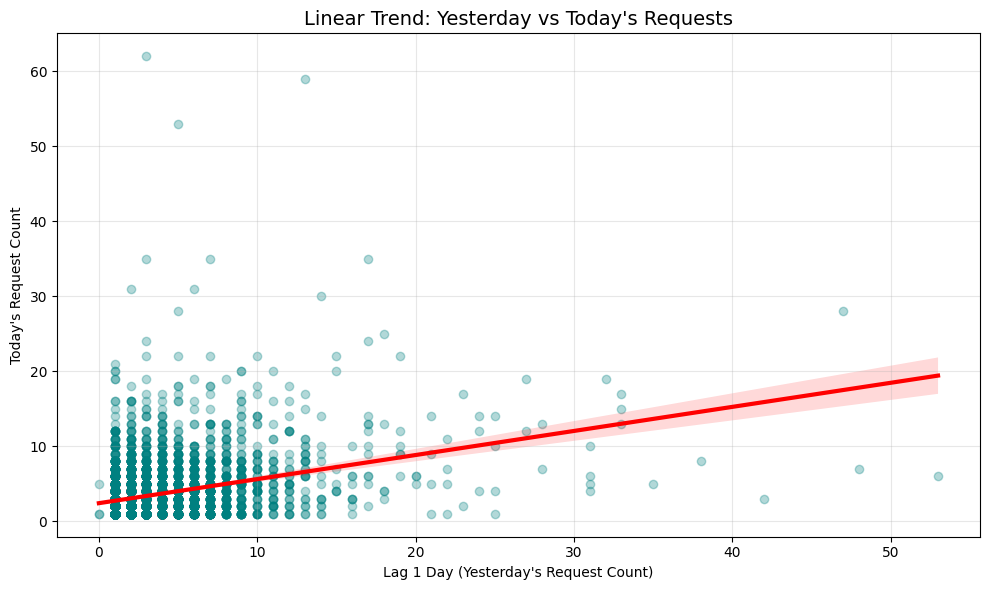

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Take the sample
df_sample = df.sample(5000)

plt.figure(figsize=(10, 6))

# sns.regplot automatically calculates and draws the linear regression line
sns.regplot(
    x='lag_request_1d', 
    y='request_count', 
    data=df_sample, 
    scatter_kws={'alpha': 0.3, 'color': 'teal'}, # Makes the dots transparent
    line_kws={'color': 'red', 'linewidth': 3}    # Draws a thick red trend line
)

plt.xlabel("Lag 1 Day (Yesterday's Request Count)")
plt.ylabel("Today's Request Count")
plt.title("Linear Trend: Yesterday vs Today's Requests", fontsize=14)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

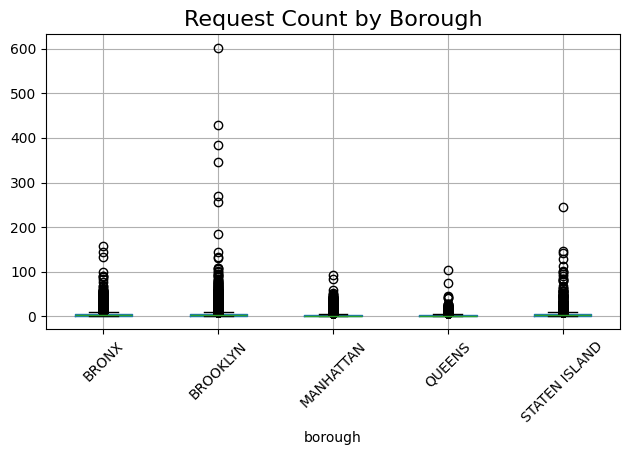

In [38]:
plt.figure(figsize=(12, 6))

df.boxplot(column='request_count', by='borough')

plt.xticks(rotation=45)
plt.title("Request Count by Borough", fontsize=16)
plt.suptitle("")  

plt.tight_layout()
plt.show()

In [15]:
# The mathematically correct columns to drop based on your VIF results
cols_to_drop = [
    'tmax',           # Redundant (we are keeping temp_range instead)
    'tmin',           # Redundant (we are keeping temp_range instead)
    'day_of_year',    # Severe Multicollinearity (VIF 141) - keeping 'month' instead
    'prcp_category'   # Drop this because it was just a temporary column we made for the boxplot
]

df_clean = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

### since these had little to no effect on request and tmax is contributing to multicolinearity

In [18]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 160951 entries, 0 to 161612
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   incident_zip          160951 non-null  int64  
 1   date                  160951 non-null  object 
 2   borough               160951 non-null  object 
 3   request_count         160951 non-null  int64  
 4   complaint_type_count  160951 non-null  int64  
 5   year                  160951 non-null  int64  
 6   month                 160951 non-null  int64  
 7   day_of_week           160951 non-null  int64  
 8   season                160951 non-null  int64  
 9   is_weekend            160951 non-null  int64  
 10  is_holiday            160951 non-null  int64  
 11  prcp                  160951 non-null  float64
 12  snow                  160951 non-null  float64
 13  snwd                  160951 non-null  float64
 14  awnd                  160951 non-null  float64
 15  temp_

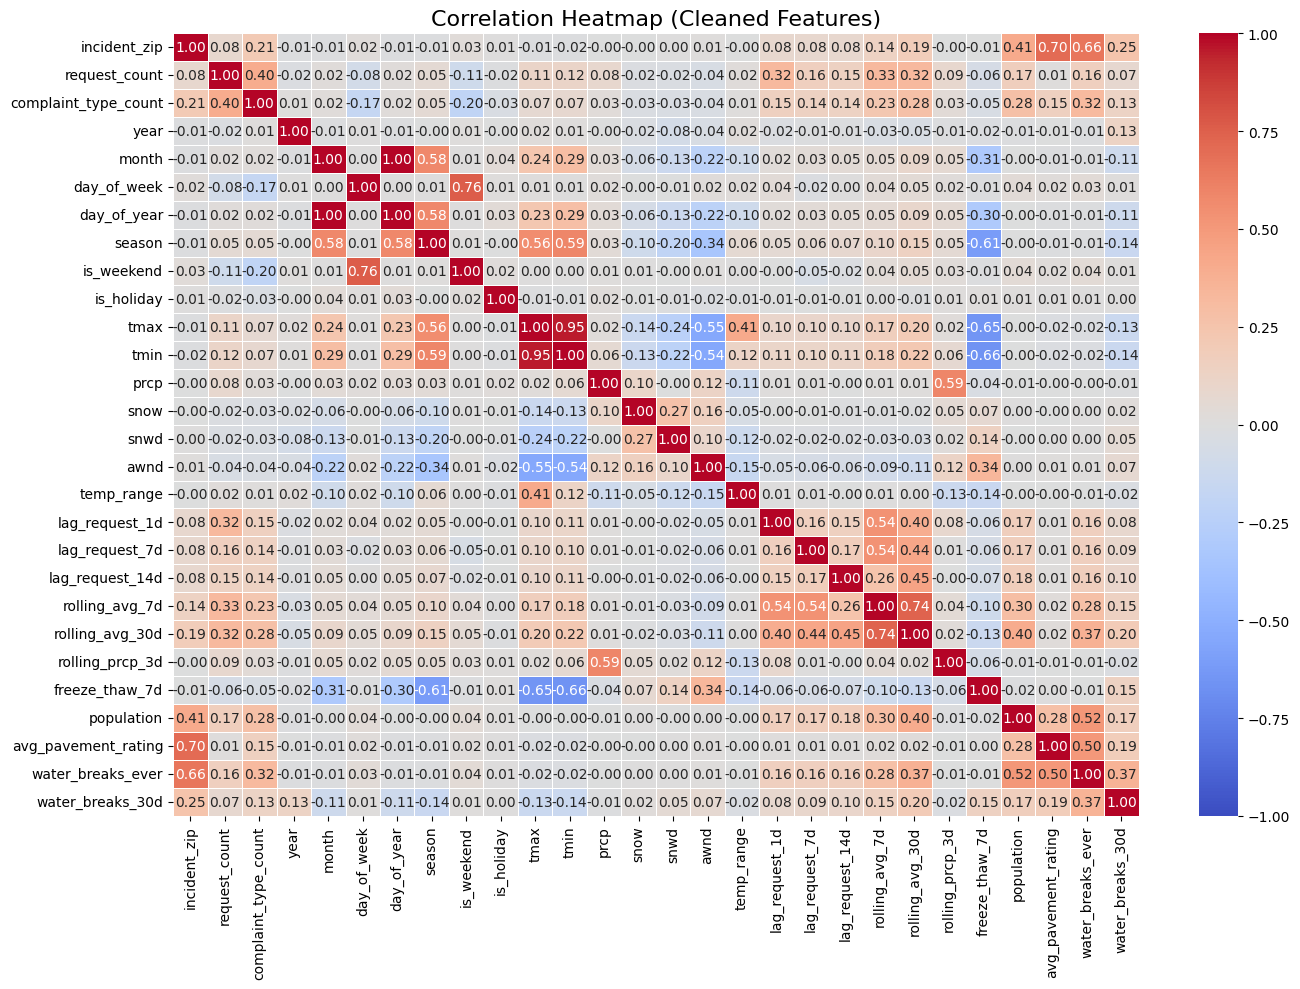

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

# Seaborn handles the colors, the annotations (annot=True), and the axis labels automatically!
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)

plt.title("Correlation Heatmap (Cleaned Features)", fontsize=16)
plt.tight_layout()
plt.show()

### to reduce the impact of outliers we have represented then in log form so keep things tidy and small values meaningful

In [42]:
import numpy as np

df_clean['request_count_log'] = np.log1p(df_clean['request_count'])

In [43]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 160951 entries, 0 to 161612
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   incident_zip          160951 non-null  int64  
 1   date                  160951 non-null  object 
 2   borough               160951 non-null  object 
 3   request_count         160951 non-null  int64  
 4   complaint_type_count  160951 non-null  int64  
 5   year                  160951 non-null  int64  
 6   month                 160951 non-null  int64  
 7   day_of_week           160951 non-null  int64  
 8   season                160951 non-null  int64  
 9   is_weekend            160951 non-null  int64  
 10  is_holiday            160951 non-null  int64  
 11  prcp                  160951 non-null  float64
 12  snow                  160951 non-null  float64
 13  snwd                  160951 non-null  float64
 14  awnd                  160951 non-null  float64
 15  temp_

In [44]:
df_clean.sample(10)

,incident_zip,date,borough,request_count,complaint_type_count,year,month,day_of_week,season,is_weekend,is_holiday,prcp,snow,snwd,awnd,temp_range,lag_request_1d,lag_request_7d,lag_request_14d,rolling_avg_7d,rolling_avg_30d,rolling_prcp_3d,freeze_thaw_7d,population,avg_pavement_rating,water_breaks_ever,water_breaks_30d
7373,10010,2022-07-29,MANHATTAN,3,1,2022,7,4,2,0,0,2.5,0.0,0.0,1.5,7.2,6.0,1.0,1.0,3.428571,1.933333,3.0,0.0,32410.0,6.75,6,0.0
126208,11215,2022-10-14,BROOKLYN,4,1,2022,10,4,3,0,0,4.8,0.0,0.0,1.7,8.3,7.0,6.0,4.0,3.571429,9.366667,25.1,0.0,72014.0,7.28,361,3.0
43774,10301,2023-03-24,STATEN ISLAND,2,2,2023,3,4,1,0,0,0.0,0.0,0.0,2.3,6.1,1.0,6.0,5.0,4.428571,3.133333,2.3,1.0,40331.0,6.81,110,0.0
86896,10469,2020-08-16,BRONX,4,2,2020,8,6,2,1,0,5.3,0.0,0.0,3.5,2.8,4.0,4.0,1.0,7.714286,8.100000,5.3,0.0,71862.0,6.33,142,2.0
29934,10032,2021-09-22,MANHATTAN,5,4,2021,9,2,3,0,0,0.3,0.0,0.0,0.7,3.9,2.0,3.0,2.0,2.857143,3.100000,0.3,0.0,60480.0,6.75,23,0.0
97107,11101,2021-07-28,QUEENS,3,1,2021,7,2,2,0,0,3.6,0.0,0.0,1.6,6.6,5.0,12.0,3.0,4.714286,4.000000,23.4,0.0,34279.0,6.81,269,2.0
120894,11212,2021-02-27,BROOKLYN,3,2,2021,2,5,0,1,0,9.9,0.0,0.0,2.1,6.7,7.0,6.0,1.0,5.714286,3.466667,9.9,1.0,84006.0,7.28,130,6.0
31291,10033,2022-03-02,MANHATTAN,1,1,2022,3,2,1,0,0,0.0,0.0,0.0,2.4,6.7,1.0,1.0,1.0,1.857143,2.300000,0.0,1.0,58711.0,6.75,16,3.0
33930,10035,2022-10-05,MANHATTAN,4,2,2022,10,2,3,0,0,9.4,0.0,0.0,2.4,2.8,3.0,8.0,1.0,4.285714,3.466667,68.3,0.0,38595.0,6.75,11,0.0
81246,10465,2022-07-10,BRONX,2,2,2022,7,6,2,1,0,0.0,0.0,0.0,2.6,8.9,1.0,1.0,3.0,4.000000,5.833333,6.1,0.0,46311.0,6.33,112,1.0


### since we have request_count_logs i am removing request_count to reeduce the size of model

### Cyclical Encoding: We use sine and cosine transformations to ensure the model recognizes that cyclical time periods, like December and January or Sunday and Monday, are chronologically close together.

### Weather-Infrastructure Interactions: We combine weather and road data to help the model identify high-risk scenarios where environmental stress directly amplifies infrastructure failure.

### Trend Velocity: We calculate the difference between short-term and long-term averages to detect whether complaint volumes are currently accelerating or stabilizing compared to historical norms.

### Target Transformation: We apply a log scale to the complaint counts to reduce the influence of extreme outliers and create a more uniform distribution that is easier for the model to learn.

In [48]:
df_clean.columns

Index(['incident_zip', 'date', 'borough', 'request_count',
       'complaint_type_count', 'year', 'month', 'day_of_week', 'season',
       'is_weekend', 'is_holiday', 'prcp', 'snow', 'snwd', 'awnd',
       'temp_range', 'lag_request_1d', 'lag_request_7d', 'lag_request_14d',
       'rolling_avg_7d', 'rolling_avg_30d', 'rolling_prcp_3d',
       'freeze_thaw_7d', 'population', 'avg_pavement_rating',
       'water_breaks_ever', 'water_breaks_30d'],
      dtype='object')

In [51]:
# First, ensure the date column is in datetime format
df_clean['date'] = pd.to_datetime(df_clean['date'])

# Extract the missing columns needed for the feature engineering code
df_clean['month'] = df_clean['date'].dt.month
df_clean['day_of_week'] = df_clean['date'].dt.dayofweek

# Now run your feature engineering code
df_clean['month_sin'] = np.sin(2 * np.pi * df_clean['month']/12)
df_clean['month_cos'] = np.cos(2 * np.pi * df_clean['month']/12)
df_clean['day_sin'] = np.sin(2 * np.pi * df_clean['day_of_week']/7)
df_clean['day_cos'] = np.cos(2 * np.pi * df_clean['day_of_week']/7)

In [53]:
df_clean.columns

Index(['incident_zip', 'date', 'borough', 'request_count',
       'complaint_type_count', 'year', 'month', 'day_of_week', 'season',
       'is_weekend', 'is_holiday', 'prcp', 'snow', 'snwd', 'awnd',
       'temp_range', 'lag_request_1d', 'lag_request_7d', 'lag_request_14d',
       'rolling_avg_7d', 'rolling_avg_30d', 'rolling_prcp_3d',
       'freeze_thaw_7d', 'population', 'avg_pavement_rating',
       'water_breaks_ever', 'water_breaks_30d', 'month_sin', 'month_cos',
       'day_sin', 'day_cos'],
      dtype='object')

In [55]:
import lightgbm as lgb
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

# 1. The "Easy Way" Encoding: Tell LightGBM to handle zip codes natively
df_clean['incident_zip'] = df_clean['incident_zip'].astype('category')

# 2. Define your Features (X) and Target (y)
# Drop the text columns so only valid math features remain
# WE ARE USING THE RAW 'request_count' NOW!
X = df_clean.drop(columns=['request_count', 'request_count_log', 'date', 'borough'], errors='ignore')
y = df_clean['request_count'] 

# 3. Time Series Split
tscv = TimeSeriesSplit(n_splits=5)

for train_idx, test_idx in tscv.split(X):
    X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
# 4. Build the LightGBM Model
lgb_model = lgb.LGBMRegressor(
    objective='tweedie',
    n_estimators=2000,
    learning_rate=0.01,
    max_depth=8,
    num_leaves=31,
    feature_fraction=0.8,
    bagging_fraction=0.8,
    bagging_freq=5,
    random_state=42,
    n_jobs=-1
)

# 5. Train the Model
print("Training model...")
lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=100), lgb.log_evaluation(100)]
)

# 6. Evaluate the Final Accuracy
y_pred = lgb_model.predict(X_test)
print("\n--- Final Results ---")
# Removed np.expm1 since we are no longer transforming the target!
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred):.2f} complaints")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")

Training model...
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=5, subsample_freq=0 will be ignored. Current value: bagging_freq=5
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=5, subsample_freq=0 will be ignored. Current value: bagging_freq=5
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004812 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1768
[LightGBM] [Info] Number

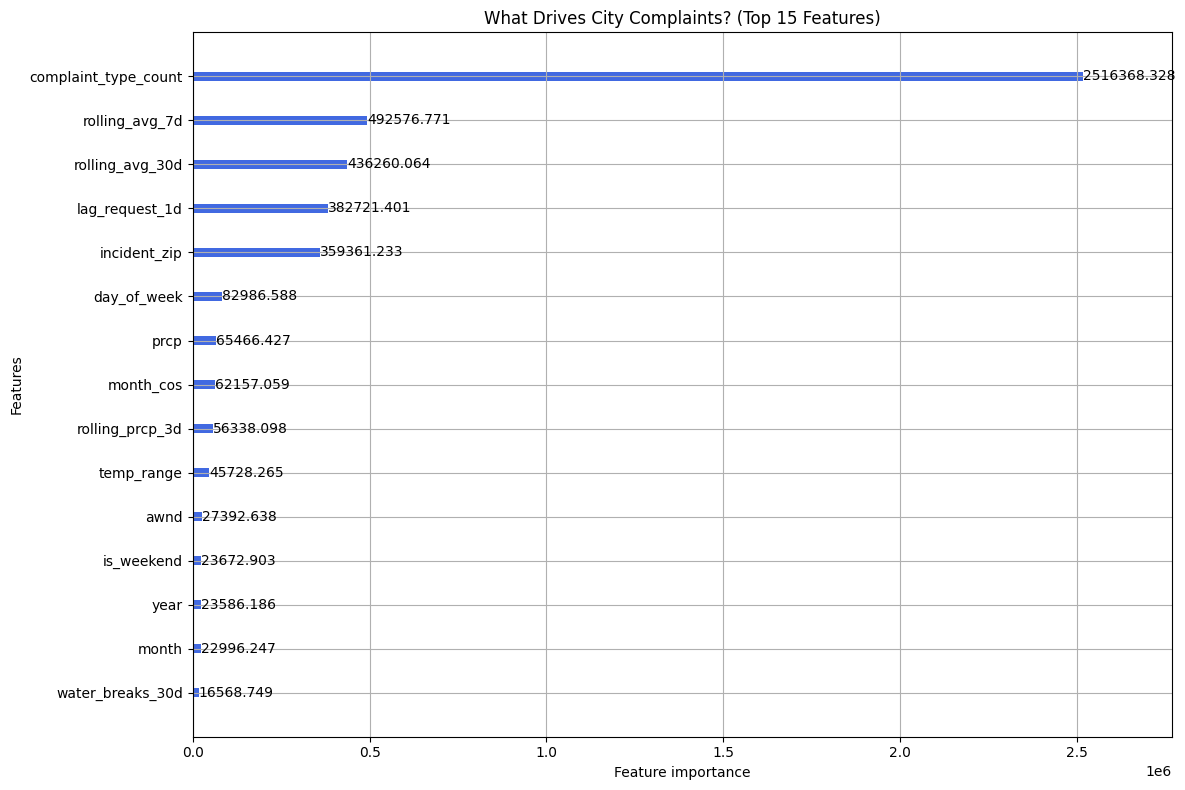

In [57]:
import matplotlib.pyplot as plt
import lightgbm as lgb

# Plot the top 15 features based on their 'gain' (mathematical contribution to predictions)
lgb.plot_importance(
    lgb_model, 
    importance_type='gain', 
    max_num_features=15, 
    figsize=(12, 8),
    title='What Drives City Complaints? (Top 15 Features)',
    color='royalblue'
)

plt.tight_layout()
plt.show()

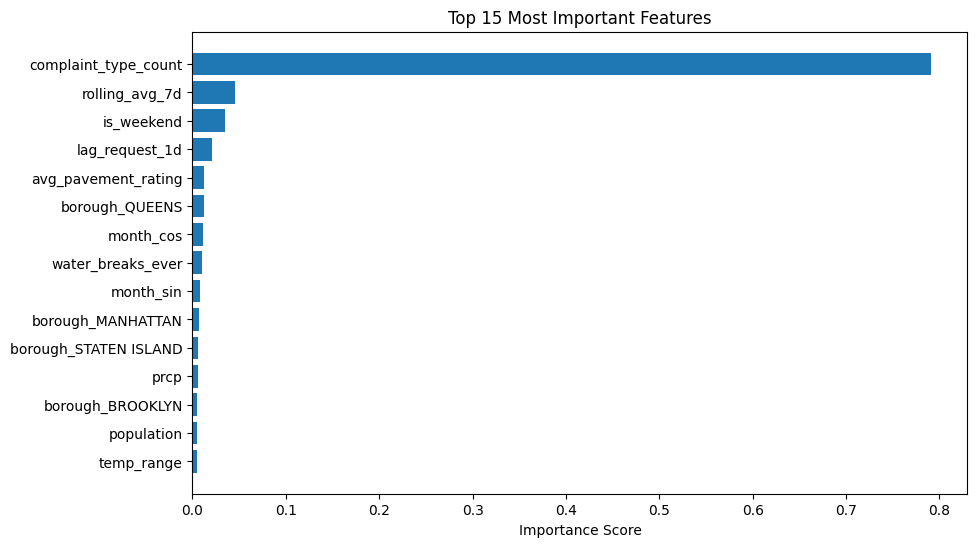

In [59]:
import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

# 1. Ensure incident_zip is a category
df_clean['incident_zip'] = df_clean['incident_zip'].astype('category')

# 2. Define Features (X) and Target (y)
# We are still using the raw 'request_count'
X = df_clean.drop(columns=['request_count', 'request_count_log', 'date', 'borough'], errors='ignore')
y = df_clean['request_count']

# 3. Time Series Split
tscv = TimeSeriesSplit(n_splits=5)

for train_idx, test_idx in tscv.split(X):
    X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# 4. Build the XGBoost Model
xgb_model = xgb.XGBRegressor(
    objective='reg:tweedie',       # XGBoost's version of the Tweedie math
    n_estimators=2000,
    learning_rate=0.01,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    enable_categorical=True,       # <--- Crucial: Tells XGBoost to handle zip codes natively!
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=100      # Stops training if it stops improving
)

# 5. Train the Model
print("Training XGBoost...")
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=100                    # Prints an update every 100 trees
)

# 6. Evaluate
y_pred = xgb_model.predict(X_test)
print("\n--- Final XGBoost Results ---")
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred):.2f} complaints")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")

Training XGBoost...
[0]	validation_0-tweedie-nloglik@1.5:7.80849
[100]	validation_0-tweedie-nloglik@1.5:7.56930
[200]	validation_0-tweedie-nloglik@1.5:7.52144
[300]	validation_0-tweedie-nloglik@1.5:7.50910
[400]	validation_0-tweedie-nloglik@1.5:7.50478
[500]	validation_0-tweedie-nloglik@1.5:7.50315
[600]	validation_0-tweedie-nloglik@1.5:7.50304
[700]	validation_0-tweedie-nloglik@1.5:7.50286
[770]	validation_0-tweedie-nloglik@1.5:7.50287

--- Final XGBoost Results ---
Mean Absolute Error: 3.30 complaints
R² Score: -0.0981


In [ ]:
###

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best Parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 1000, 'subsample': 0.8}
Tuned Mean Absolute Error: 1.46
Tuned R² Score: 0.5854


In [61]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import LabelEncoder
import numpy as np

# 1. Prepare the data
df_rf = df_clean.copy()

# Random Forest requires numeric inputs, so we Label Encode the zip codes
le = LabelEncoder()
df_rf['incident_zip'] = le.fit_transform(df_rf['incident_zip'].astype(str))

# 2. Define Features (X) and Target (y)
X = df_rf.drop(columns=['request_count', 'request_count_log', 'date', 'borough'], errors='ignore')
y = df_rf['request_count']

# 3. Time Series Split
tscv = TimeSeriesSplit(n_splits=5)
for train_idx, test_idx in tscv.split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# 4. Build the Random Forest Model
# Note: We use n_jobs=-1 to use all your CPU cores for speed
rf_model = RandomForestRegressor(
    n_estimators=100, 
    max_depth=10,      # We limit depth so it doesn't just memorize the data
    random_state=42, 
    n_jobs=-1
)

# 5. Train
print("Training Random Forest (this may take a minute)...")
rf_model.fit(X_train, y_train)

# 6. Evaluate
y_pred = rf_model.predict(X_test)
print("\n--- Final Random Forest Results ---")
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred):.2f} complaints")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")

Training Random Forest (this may take a minute)...

--- Final Random Forest Results ---
Mean Absolute Error: 1.74 complaints
R² Score: -0.0454


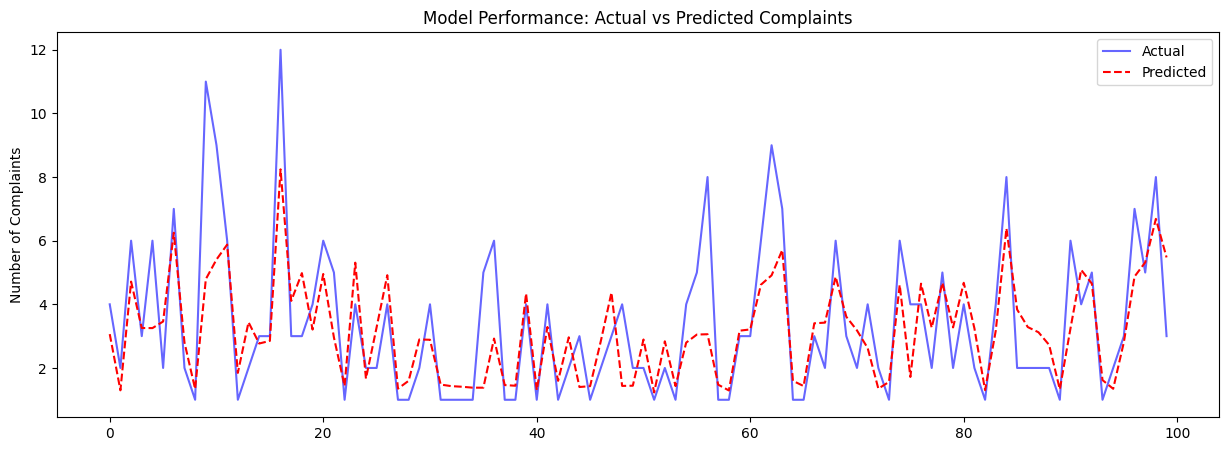

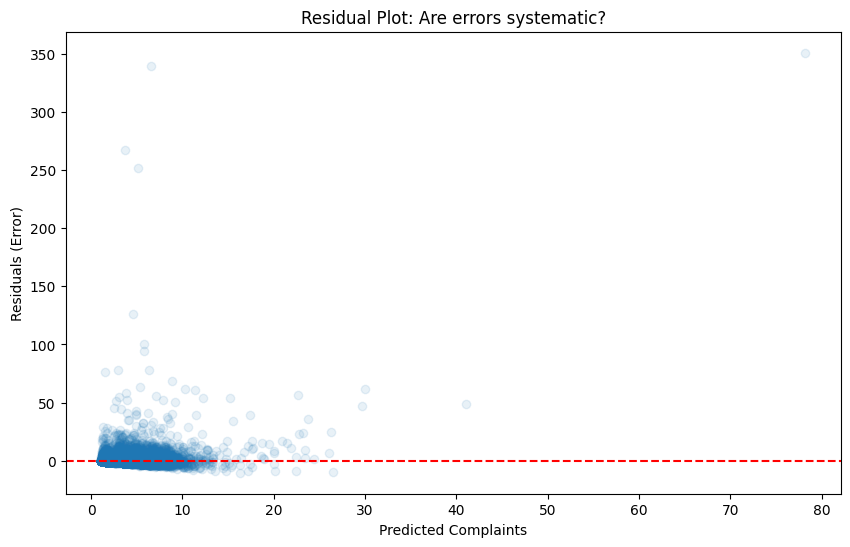

In [ ]:
!pip install lightgbm

   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.5 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1.5 MB 1.5 MB/s eta 0:00:01
   ---------------------------- ----------- 1.0/1.5 MB 1.5 MB/s eta 0:00:01
   ------------------------------------ --- 1.3/1.5 MB 1.5 MB/s eta 0:00:01
   ---------------------------------------- 1.5/1.5 MB 1.5 MB/s  0:00:01



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=5, subsample_freq=0 will be ignored. Current value: bagging_freq=5
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=5, subsample_freq=0 will be ignored. Current value: bagging_freq=5
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004565 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=tru

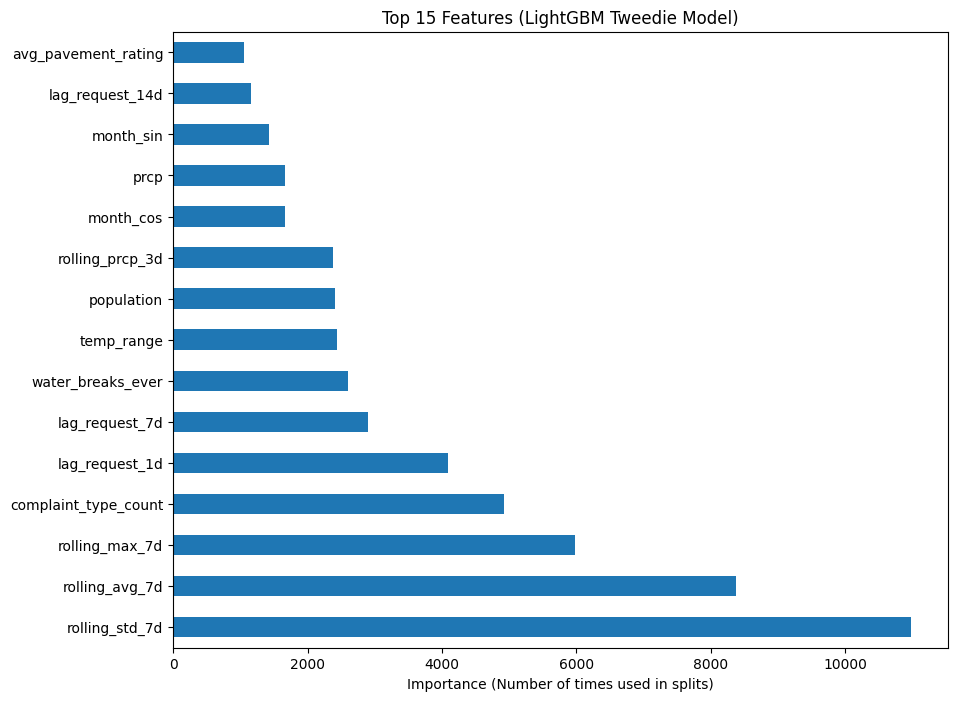

Training Base Models...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004377 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1794
[LightGBM] [Info] Number of data points in the train set: 125938, number of used features: 27
[LightGBM] [Info] Start training from score 1.291012
Final Manual Stack MAE: 1.26
Final Manual Stack R² Score: 0.6826


In [72]:
!pip install holidays

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1.4 MB 1.7 MB/s eta 0:00:01
   ----------------------------- ---------- 1.0/1.4 MB 2.0 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.0 MB/s  0:00:01



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004018 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1748
[LightGBM] [Info] Number of data points in the train set: 100750, number of used features: 27
[LightGBM] [Info] Start training from score 1.348575
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003660 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1708
[LightGBM] [Info] Number of data points in the train set: 100750, number of used features: 27
[LightGBM] [Info] Start training from score 1.307781
[LightGBM] [Warning] Found

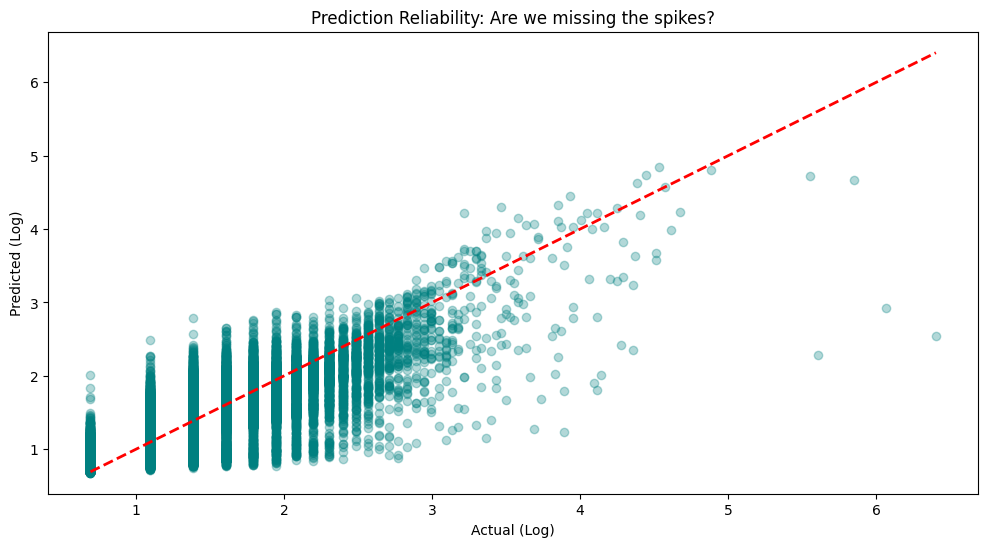